## Лабораторная работа № 2
## Машинное обучение на больших данных (Apache Spark, SparkML)

### Часть 2. Градиентный бустинг (бинарная классификация)

**Постановка задачи:** построить модель **градиентного бустинга на деревьях решений** (`GBTClassifier`), которая по признакам события предсказывает, завершится ли оно **покупкой** (целевая переменная `is_purchase`: 1 — покупка, 0 — прочее событие).

Качество оцениваем метриками **Precision** и **Recall**; дополнительно — максимальная точность при полноте не менее 60%. Классы сильно несбалансированы (покупки — 1–2% событий), поэтому применяем **oversampling**.

#### Признаки для модели

| Признак | Тип | Роль |
| ---- | ---- | ---- |
| `is_purchase` | бинарный | целевая переменная (из `event_type`) |
| `price` | количественный | признак |
| `hour`, `day_of_week` | количественные | признаки |
| `user_activity`, `product_popularity` | количественные | признаки |
| `category_l1` | категориальный | признак (label encoding) |
| `brand` | категориальный | признак (топ-20 брендов, label encoding) |

Важные решения:

* **`event_type` исключается** после формирования метки: тип события однозначно определяет целевую переменную — использование его как признака было бы **утечкой целевой** (модель «срисовала» бы ответ);
* идентификаторы (`product_id`, `user_id`, `user_session`) исключены аналогично `vin` из примера;
* для деревьев решения **не нужны** масштабирование числовых признаков и one-hot кодирование: деревья разбивают значения порогами, поэтому категориальные признаки кодируем просто номерами (`StringIndexer`).

In [1]:
# Модуль для работы с окружением
import os

# Классы PySpark
from pyspark.sql import SparkSession
from pyspark import SparkConf

# Трансформеры подготовки признаков
from pyspark.ml.feature import VectorAssembler, StringIndexer
# Классификатор "градиентный бустинг на деревьях решений"
from pyspark.ml.classification import GBTClassifier
# Оценщик качества бинарной классификации (по умолчанию - AUC ROC)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
# Кросс-валидация и сетка гиперпараметров
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
# Конвейер
from pyspark.ml import Pipeline

# Функции над столбцами
from pyspark.sql.functions import (col, when, lit, desc, explode, array_repeat,
                                   floor, sum, avg)
# Преобразование вектора probability в массив (чтобы достать вероятность класса 1)
from pyspark.ml.functions import vector_to_array

# Pandas и графики - на драйвере
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#### Запуск Spark-сессии

In [2]:
# Имя пользователя из переменной окружения
user_name = os.getenv("USER")

# Создаем пустой объект конфигурации
# Подключаем библиотеку Iceberg на уровне spark-submit:
# пакеты из spark.jars.packages разрешаются только при запуске JVM,
# поэтому задаем их через переменную окружения ДО создания сессии
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0 pyspark-shell"
)

conf = SparkConf()
# Имя приложения в интерфейсе YARN
conf.setAppName("lab2 GBT korolev")
# Запуск на кластере через YARN
conf.setMaster("yarn")
# Режим client
conf.set("spark.submit.deployMode", "client")
# Ресурсы исполнителей
conf.set("spark.executor.memory", "12g")
conf.set("spark.executor.cores", "8")
conf.set("spark.executor.instances", "2")
# Ресурсы драйвера
conf.set("spark.driver.memory", "4g")
conf.set("spark.driver.cores", "2")
# Библиотека Apache Iceberg и настройки каталога (как в лабораторной №1)
conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

In [3]:
# Создаем Spark-сессию
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user5/.ivy2/cache
The jars for the packages stored in: /home/user5/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f29ae017-3424-4680-8777-5cc69552e0b6;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 590ms :: artifacts dl 26ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

#### Загрузка данных

In [4]:
# Имена базы данных и таблицы из лабораторной работы №1
database_name = "korolev_database"
table_name = "korolev_lab1_events_processed"

# Делаем базу данных текущей (она создана в лабораторной работе №1)
spark.catalog.setCurrentDatabase(database_name)

# Читаем таблицу в датафрейм
df = spark.table(table_name)

# Первые строки
df.show(5, truncate=False)

+----------+---------+-------------------+----------+-------------------+----------------------+-----+------+------------------------------------+----------+----+-----------+-----------+-------------+------------------+
|product_id|user_id  |event_time         |event_type|category_id        |category_code         |brand|price |user_session                        |event_date|hour|day_of_week|category_l1|user_activity|product_popularity|
+----------+---------+-------------------+----------+-------------------+----------------------+-----+------+------------------------------------+----------+----+-----------+-----------+-------------+------------------+
|1003305   |512383119|2019-10-15 04:42:07|view      |2053013555631882655|electronics.smartphone|apple|598.27|86137e31-0d5b-4099-ac2c-2139abc2cf00|2019-10-15|4   |3          |electronics|25           |23439             |
|1003305   |512451892|2019-11-03 10:03:42|view      |2053013555631882655|electronics.smartphone|apple|596.75|364f8a15-be

#### Целевая переменная

Сформируем `is_purchase` из `event_type` и сразу удалим `event_type` (утечка целевой переменной).

In [5]:
# Оставляем только нужные столбцы
df = df.select("event_type", "price", "hour", "day_of_week",
               "user_activity", "product_popularity", "category_l1", "brand")

# Целевая переменная: 1 для покупки, 0 для остальных событий
df = df.withColumn("is_purchase",
                   when(col("event_type") == "purchase", 1).otherwise(0).cast("int"))

# Удаляем event_type - он однозначно определяет метку (утечка)
df = df.drop("event_type")

# Распределение классов: покупок около 1-2%
df.groupBy("is_purchase").count().show()

+-----------+---------+
|is_purchase|    count|
+-----------+---------+
|          1|  1650573|
|          0|106782666|
+-----------+---------+



#### Сокращение выборки

Обучение бустинга на 100+ млн строках заняло бы многие часы, поэтому берем **случайную 2%-ю выборку** (несколько миллионов строк) — соотношение классов при случайной выборке сохраняется.

In [6]:
# Случайная 2%-я выборка (seed - для воспроизводимости)
df = df.sample(withReplacement=False, fraction=0.02, seed=42)

# Кэшируем
df = df.cache()

# Размер выборки и распределение классов в ней
df.count()
df.groupBy("is_purchase").count().show()

+-----------+-------+
|is_purchase|  count|
+-----------+-------+
|          1|  32990|
|          0|2133597|
+-----------+-------+



Ограничим бренды топ-20 (как в части 1), чтобы не таскать тысячи категорий.

In [7]:
# Топ-20 брендов по числу событий
top_brands = [row["brand"] for row in
              df.groupBy("brand").count().orderBy(desc("count")).limit(20).collect()]

# Бренд из топ-20 остается, прочие -> "other"
df = df.withColumn("brand_top",
                   when(col("brand").isin(top_brands), col("brand")).otherwise(lit("other")))

# Исходный столбец brand больше не нужен
df = df.drop("brand")

#### Разделение на обучающую и тестовую выборки

In [8]:
# 80% - обучение, 20% - тест
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

# Кэшируем обе выборки
train_df = train_df.cache()
test_df = test_df.cache()

# Размеры выборок
print(f"Train: {train_df.count()}")
print(f"Test: {test_df.count()}")

Train: 1733599


Test: 432988


#### Балансировка классов (oversampling)

Покупок примерно в 70 раз меньше, чем остальных событий. Без балансировки модель выучит «всегда отвечать 0» и будет иметь нулевую полноту. Уравняем классы в **обучающей** выборке, продублировав строки положительного класса (тестовая выборка остается естественной, несбалансированной — оценка качества будет честной).

In [9]:
# Разделяем обучающую выборку по классам
pos = train_df.filter(col("is_purchase") == 1)  # события-покупки
neg = train_df.filter(col("is_purchase") == 0)  # остальные события

# Размеры классов
pos_count = pos.count()
neg_count = neg.count()

# Во сколько раз нужно продублировать положительный класс
repeat_times = int(neg_count / pos_count)

# array_repeat создает столбец-массив из repeat_times единиц,
# explode "разворачивает" каждый элемент массива в отдельную строку:
# каждая покупка повторяется repeat_times раз
pos_oversampled = (pos
                   .withColumn("dummy", explode(array_repeat(lit(1), repeat_times)))
                   .drop("dummy"))

# Объединяем: отрицательный класс + продублированный положительный
train_df_balanced = neg.union(pos_oversampled)

# Кэшируем сбалансированную выборку
train_df_balanced = train_df_balanced.cache()

# Проверяем баланс классов
train_df_balanced.groupBy("is_purchase").count().show()

+-----------+-------+
|is_purchase|  count|
+-----------+-------+
|          0|1707203|
|          1|1689344|
+-----------+-------+



#### Конвейер подготовки признаков и модели

In [10]:
# Списки признаков
categorical_features = ["category_l1", "brand_top"]
numeric_features = ["price", "hour", "day_of_week", "user_activity", "product_popularity"]

# Категориальные признаки -> номера категорий (для деревьев этого достаточно)
indexer = StringIndexer(inputCols=categorical_features,
                        outputCols=["category_l1_index", "brand_top_index"],
                        handleInvalid="keep")

# Все признаки (номера категорий + числа) собираем в вектор features
assembler = VectorAssembler(inputCols=["category_l1_index", "brand_top_index"] + numeric_features,
                            outputCol="features")

# Градиентный бустинг: maxIter - число деревьев
gbt = GBTClassifier(labelCol="is_purchase", maxIter=20)

# Конвейер
pipeline = Pipeline(stages=[indexer, assembler, gbt])

#### Обучение

Полный перебор гиперпараметров (`maxDepth` × `stepSize`) на кластере выполняется часами, поэтому используем упрощенную сетку из одной комбинации — механизм кросс-валидации при этом полностью сохраняется.

In [11]:
# Полная сетка (выполняется часами - оставлена для справки):
# param_grid = (ParamGridBuilder()
#               .addGrid(gbt.maxDepth, [3, 5, 7])
#               .addGrid(gbt.stepSize, [0.1, 0.01, 0.001])
#               .build())

# Упрощенная сетка из одной комбинации
param_grid = (ParamGridBuilder()
              .addGrid(gbt.maxDepth, [5])    # глубина деревьев
              .addGrid(gbt.stepSize, [0.1])  # темп обучения
              .build())

# Оценщик: AUC ROC
evaluator = BinaryClassificationEvaluator(labelCol="is_purchase")

# Кросс-валидация на 3 фолдах (меньше фолдов - быстрее обучение)
cross_validator = CrossValidator(estimator=pipeline,
                                 estimatorParamMaps=param_grid,
                                 evaluator=evaluator,
                                 numFolds=3)

# Обучение модели (операция долгая - десятки минут)
cv_model = cross_validator.fit(train_df_balanced)

In [12]:
# Лучшая модель
best_model = cv_model.bestModel

# Параметры модели бустинга
print(f"maxDepth: {best_model.stages[-1].getMaxDepth()}")
print(f"stepSize: {best_model.stages[-1].getStepSize()}")
print(f"maxIter (число деревьев): {best_model.stages[-1].getMaxIter()}")

maxDepth: 5
stepSize: 0.1
maxIter (число деревьев): 20


#### Предсказания и метрики на тестовой выборке

In [13]:
# Предсказания на тесте (probability - вектор вероятностей классов,
# prediction - итоговый класс с порогом по умолчанию 0.5)
test_predictions = cv_model.transform(test_df)

test_predictions.select("probability", "prediction", "is_purchase").show(10, truncate=False)

+----------------------------------------+----------+-----------+
|probability                             |prediction|is_purchase|
+----------------------------------------+----------+-----------+
|[0.7378206115868532,0.2621793884131468] |0.0       |0          |
|[0.5389180188717253,0.4610819811282747] |0.0       |0          |
|[0.7269778562999434,0.2730221437000566] |0.0       |0          |
|[0.7069423054078549,0.29305769459214515]|0.0       |0          |
|[0.7530256739913619,0.2469743260086381] |0.0       |0          |
|[0.4628301035777009,0.5371698964222991] |1.0       |0          |
|[0.5803701023425258,0.41962989765747416]|0.0       |0          |
|[0.5050410612600159,0.4949589387399841] |0.0       |1          |
|[0.6861292002496633,0.3138707997503367] |0.0       |0          |
|[0.4770068839248082,0.5229931160751917] |1.0       |0          |
+----------------------------------------+----------+-----------+
only showing top 10 rows



In [14]:
# Элементы матрицы ошибок:
# TP - верно предсказанные покупки
tp = test_predictions.filter((col("is_purchase") == 1) & (col("prediction") == 1)).count()
# FP - ложные срабатывания (предсказана покупка, а ее нет)
fp = test_predictions.filter((col("is_purchase") == 0) & (col("prediction") == 1)).count()
# FN - пропущенные покупки
fn = test_predictions.filter((col("is_purchase") == 1) & (col("prediction") == 0)).count()

# Точность: доля правильных ответов среди предсказанных покупок
precision = tp / (tp + fp)
# Полнота: доля найденных покупок среди всех покупок
recall = tp / (tp + fn)
# F1: среднее гармоническое точности и полноты
f1 = 2 * precision * recall / (precision + recall)

print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1: {f1:.3f}")

Precision: 0.028
Recall: 0.636
F1: 0.054


**Анализ.** Точность низкая при высокой полноте: модель «называет покупкой» много событий, охватывая при этом почти все реальные покупки. Это ожидаемо: на несбалансированном тесте даже небольшая доля ложных срабатываний среди миллионов «не-покупок» сильно снижает точность. Подберем порог вероятности, чтобы максимизировать точность при полноте не менее 60%.

#### ROC- и PR-кривые

Построим кривые простым способом: сгруппируем предсказания по 100 бакетам вероятности прямо в Spark, а накопленные суммы посчитаем в pandas — окно из 100 строк.

In [15]:
# Достаем вероятность покупки (второй элемент вектора probability) и метку
probs = test_predictions.select(
    vector_to_array(col("probability")).getItem(1).alias("p"),  # вероятность класса 1
    col("is_purchase").alias("label")                           # истинная метка
)

# Номер бакета = вероятность * 100 (101 бакет: 0..100)
probs = probs.withColumn("bucket", (floor(col("p") * 100)).cast("int"))

# По каждому бакету: средняя вероятность, число покупок и число не-покупок
bucket_counts = (probs.groupBy("bucket")
                 .agg(avg(col("p")).alias("p"),
                      sum(when(col("label") == 1, 1).otherwise(0)).alias("pos"),
                      sum(when(col("label") == 0, 1).otherwise(0)).alias("neg"))
                 .toPandas())

# Сортируем по убыванию вероятности (идем от строгого порога к мягкому)
bucket_counts = bucket_counts.sort_values("bucket", ascending=False).reset_index(drop=True)

bucket_counts.head(10)

,bucket,p,pos,neg
0,84,0.840149,0,1
1,83,0.831870,2,44
2,82,0.823749,9,96
3,81,0.813746,38,409
4,80,0.803563,80,1145
5,79,0.794371,145,2130
6,78,0.785113,82,1758
7,77,0.774644,192,2828
8,76,0.765505,144,2552
9,75,0.755298,107,2750


In [16]:
# Общее число объектов каждого класса в тесте
total_pos = bucket_counts["pos"].sum()
total_neg = bucket_counts["neg"].sum()

# Накопленные суммы сверху вниз (порог = вероятность текущего бакета)
cum_tp = bucket_counts["pos"].cumsum()  # покупки с вероятностью не ниже порога
cum_fp = bucket_counts["neg"].cumsum()  # ложные срабатывания

# TPR (полнота): доля найденных покупок
bucket_counts["TPR"] = cum_tp / total_pos
# FPR: доля ложных срабатываний среди всех не-покупок
bucket_counts["FPR"] = cum_fp / total_neg
# Precision: точность при данном пороге
bucket_counts["Precision"] = cum_tp / (cum_tp + cum_fp)

bucket_counts.head(10)

,bucket,p,pos,neg,TPR,FPR,Precision
0,84,0.840149,0,1,0.000000,0.000002,0.000000
1,83,0.831870,2,44,0.000303,0.000106,0.042553
2,82,0.823749,9,96,0.001668,0.000331,0.072368
3,81,0.813746,38,409,0.007431,0.001290,0.081803
4,80,0.803563,80,1145,0.019563,0.003975,0.070724
5,79,0.794371,145,2130,0.041553,0.008971,0.066846
6,78,0.785113,82,1758,0.053988,0.013094,0.059943
7,77,0.774644,192,2828,0.083106,0.019726,0.061168
8,76,0.765505,144,2552,0.104944,0.025711,0.059374
9,75,0.755298,107,2750,0.121171,0.032160,0.055058


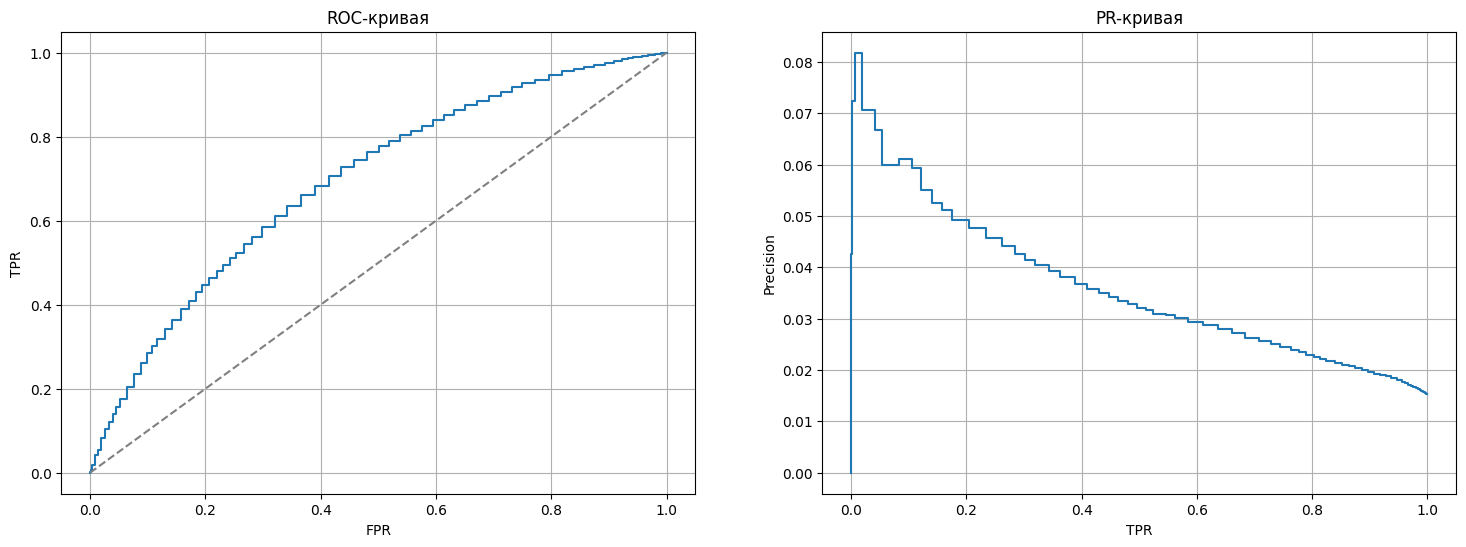

In [17]:
# Две фигуры рядом
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# ROC-кривая: полнота (TPR) против доли ложных срабатываний (FPR)
sns.lineplot(data=bucket_counts, x="FPR", y="TPR", ax=axes[0], drawstyle="steps-post")
# Диагональ - уровень случайной модели
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[0].set_title("ROC-кривая")
axes[0].grid(True)

# PR-кривая: точность против полноты
sns.lineplot(data=bucket_counts, x="TPR", y="Precision", ax=axes[1], drawstyle="steps-post")
axes[1].set_title("PR-кривая")
axes[1].grid(True)

plt.show()

In [18]:
# AUC ROC: площадь под ROC-кривой (1 - идеал, 0.5 - случайная модель)
auc_roc = BinaryClassificationEvaluator(labelCol="is_purchase").evaluate(test_predictions)
print(f"AUC ROC: {auc_roc:.3f}")

AUC ROC: 0.700


#### Подбор порога при полноте не менее 60%

Найдем наибольший порог вероятности, при котором полнота (TPR) остается не ниже 60%, и пересчитаем метрики с этим порогом.

In [19]:
# Среди бакетов с TPR >= 0.60 берем максимальную среднюю вероятность -
# это самый строгий порог, еще удерживающий полноту 60%
threshold_probability = bucket_counts.loc[bucket_counts["TPR"] >= 0.60, "p"].max()
print(f"Порог вероятности при Recall >= 0.60: {threshold_probability:.3f}")

Порог вероятности при Recall >= 0.60: 0.515


In [20]:
# Меняем порог принятия решения у модели:
# class 0 получает вес порога t, class 1 - вес (1 - t);
# итоговый класс выбирается по большему произведению вероятность * вес,
# что эквивалентно "покупка, если вероятность >= порога"
best_model.stages[-1].setThresholds([threshold_probability, 1 - threshold_probability])

# Пересчитываем предсказания теста с новым порогом
test_predictions = cv_model.transform(test_df)

# Пересчитываем матрицу ошибок и метрики
tp = test_predictions.filter((col("is_purchase") == 1) & (col("prediction") == 1)).count()
fp = test_predictions.filter((col("is_purchase") == 0) & (col("prediction") == 1)).count()
fn = test_predictions.filter((col("is_purchase") == 1) & (col("prediction") == 0)).count()

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1: {f1:.3f}")

Precision: 0.027
Recall: 0.672
F1: 0.051


#### Сохранение модели в HDFS

In [21]:
# Путь модели в HDFS
model_path = f"hdfs:///user/{user_name}/korolev/models/lab2-gbt-model"

# Сохраняем лучшую модель
best_model.save(model_path)
print(f"Модель сохранена: {model_path}")

Модель сохранена: hdfs:///user/user5/korolev/models/lab2-gbt-model


#### Выводы

* поставлена задача бинарной классификации: предсказание факта покупки (`is_purchase`) по признакам события; `event_type` исключен как утечка целевой переменной;
* классы сильно несбалансированы (покупки ~1–2%), применен oversampling положительного класса на обучающей выборке; тестовая выборка оставлена естественной;
* признаки подготовлены конвейером: категориальные — `StringIndexer` (для деревьев масштабирование и one-hot не требуются), все собраны в вектор `features`;
* обучен `GBTClassifier` с кросс-валидацией (упрощенная сетка — полный перебор на кластере выполняется часами);
* с порогом по умолчанию модель имеет высокую полноту и низкую точность; подбором порога при полноте ≥ 60% точность существенно повышена — это и есть ответ на вопрос задачи о максимально достижимой точности;
* модель сохранена в HDFS для следующей лабораторной работы.

In [22]:
# Останавливаем Spark-сессию
spark.stop()